# 01 — Dữ liệu: nguồn, làm sạch, mất cân bằng

> Notebook trình bày, **không huấn luyện lại**. Mọi bảng và hình được tính từ file kết quả đã lưu trong `saved/`, chạy lại an toàn trên CPU. Log huấn luyện đã được rút gọn (bỏ thanh tiến độ, giữ mọi kết quả eval); bản đầy đủ nằm trong `ASR/notebooks/local` và `ASR/local/logs`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
S = next(p / 'saved' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'saved/tables').is_dir())
T = S / 'tables'
def js(rel): return json.loads((S / rel).read_text(encoding='utf-8'))
def show_log(name): print((S / 'logs' / name).read_text(encoding='utf-8'))
def history(name): return js(f'runs/{name}_trainer_state.json')['log_history']
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'Baseline 1': '#7E9C9B', 'Baseline 2': '#A9C2C0', 'V1': '#0F4E57', 'V2': '#1A6771', 'V-Final': '#FFB21A'}

## 1.1 Nguồn dữ liệu
Cả 4 nguồn là dữ liệu công khai (Online). Nhóm không thu dữ liệu Offline. Sau xử lý: FLAC 16 kHz mono trong parquet,
các trường `id, source, split, group_id, speaker_id, text, cs_terms, duration, audio`.

In [2]:
d = pd.read_csv(T / 'data_stats_by_source_split.csv')
print('Số clip (ViMedCSS_vsplit = ViMedCSS chia lại theo video, dùng cho thí nghiệm thành phần ở 06)')
display(d.pivot_table(index='source', columns='split', values='clips', aggfunc='sum', fill_value=0)[['train', 'dev', 'test', 'hard']])
print('Số giờ')
d.pivot_table(index='source', columns='split', values='hours', aggfunc='sum', fill_value=0)[['train', 'dev', 'test', 'hard']].round(1)

Số clip (ViMedCSS_vsplit = ViMedCSS chia lại theo video, dùng cho thí nghiệm thành phần ở 06)


split,train,dev,test,hard
source,,,,
FLEURS,2994,361,857,0
VIVOS,11476,184,760,0
ViMedCSS,11832,1714,1614,658
ViMedCSS_vsplit,12688,1523,1539,71
VietMed,2773,2912,3437,0


Số giờ


split,train,dev,test,hard
source,,,,
FLEURS,9.1,1.2,3.0,0.0
VIVOS,14.6,0.3,0.7,0.0
ViMedCSS,22.9,3.4,3.2,1.3
ViMedCSS_vsplit,24.8,3.0,2.9,0.1
VietMed,4.8,5.0,6.0,0.0


In [3]:
pd.read_csv(T / 'split_ratio_official.csv').set_index('split')

,clips,hours,words,clips_pct,hours_pct,words_pct
split,,,,,,
dev,5171,9.85,128087,12.64,13.27,14.24
test,6668,12.97,153292,16.30,17.47,17.05
train,29075,51.42,617949,71.06,69.26,68.71


## 1.2 Làm sạch (đếm từ file kết quả)

In [4]:
lk, ex = js('tables/leakage_before_after.json'), js('runs/train_exclude.json')
pd.DataFrame([
    ['Trùng lặp (ViMedCSS)', lk['after']['dropped_duplicates']],
    ['Clip im lặng, đỉnh biên độ < 0,001', lk['after']['dropped_silent']],
    ['Nhãn dày bất thường (> 16 token/giây), chỉ bỏ khỏi Train', len(ex['ids'])],
], columns=['Bước', 'Số clip loại'])

,Bước,Số clip loại
0,Trùng lặp (ViMedCSS),4
1,"Clip im lặng, đỉnh biên độ < 0,001",64
2,"Nhãn dày bất thường (> 16 token/giây), chỉ bỏ ...",14


Thêm: 10 clip audio rỗng của ViMedCSS train bị loại khi nạp dữ liệu (dòng `Exclude ViMedCSS/train` trong log huấn luyện ở `03_V1`). Văn bản: NFC, chữ thường, bỏ dấu câu, cùng một luật khi huấn luyện và khi chấm. Nhãn thuật ngữ `cs_terms` do tác giả ViMedCSS cung cấp; nhóm không gán nhãn thủ công nên không có Kappa.

## 1.3 Mất cân bằng

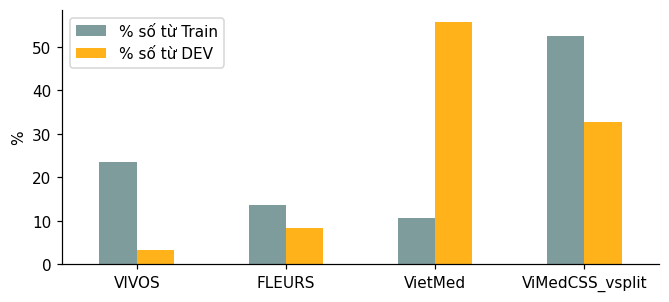

,% số từ Train,% số từ DEV
VIVOS,23.38,3.26
FLEURS,13.50,8.41
VietMed,10.57,55.64
ViMedCSS_vsplit,52.55,32.69


In [5]:
im = js('tables/imbalance.json')
w = pd.DataFrame({'% số từ Train': im['train_word_share_pct'], '% số từ DEV': im['dev_word_share_pct']})
ax = w.plot.bar(figsize=(7, 3), color=['#7E9C9B', '#FFB21A'], rot=0); ax.set_ylabel('%'); plt.show()
w

In [6]:
print(f"Thuật ngữ trong Train: {im['train_term_distinct']} loại, {im['train_term_occurrences']:,} lượt".replace(',', '.'))
print(f"Chỉ xuất hiện 1 lần: {im['terms_seen_once']}; dưới 5 lần: {im['terms_seen_lt5']}")
print(f"Top-10 thuật ngữ chiếm {im['top10_share_pct']:.1f}% số lượt; riêng '{im['top1_term']}' chiếm {im['top1_share_pct']:.1f}%")

Thuật ngữ trong Train: 831 loại. 13.295 lượt
Chỉ xuất hiện 1 lần: 173; dưới 5 lần: 390
Top-10 thuật ngữ chiếm 22.5% số lượt; riêng 'virus' chiếm 6.0%


Thống kê thuật ngữ ở trên tính trên bản chia ViMedCSS theo video (831 loại). Train chính thức có 610 loại (bảng 1.4).

## 1.4 Xử lý mất cân bằng: oversampling clip chứa thuật ngữ hiếm (≤ 5 lần) × 3

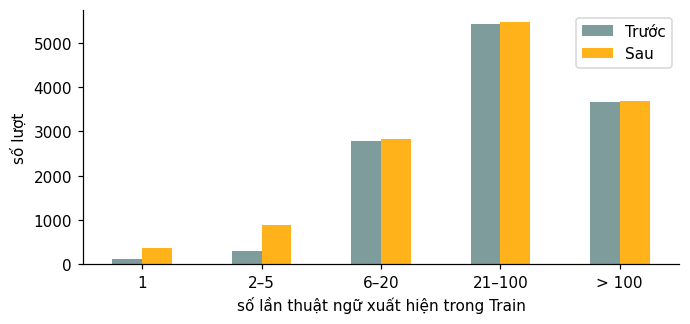

Lượt thuật ngữ hiếm: 412 → 1236; tỷ lệ 3.35% → 9.35%


,distinct_terms,occ_before,occ_after
term_count_bucket,,,
1,120,120,360
2–5,90,292,876
6–20,248,2792,2836
21–100,136,5425,5469
> 100,16,3665,3679


In [7]:
o = pd.read_csv(T / 'term_oversampling.csv').set_index('term_count_bucket')
ax = o[['occ_before', 'occ_after']].rename(columns={'occ_before': 'Trước', 'occ_after': 'Sau'}).plot.bar(figsize=(7, 3), color=['#7E9C9B', '#FFB21A'], rot=0)
ax.set_xlabel('số lần thuật ngữ xuất hiện trong Train'); ax.set_ylabel('số lượt'); plt.show()
rare = o.loc[['1', '2–5']]
print(f"Lượt thuật ngữ hiếm: {rare.occ_before.sum()} → {rare.occ_after.sum()}; tỷ lệ {100 * rare.occ_before.sum() / o.occ_before.sum():.2f}% → {100 * rare.occ_after.sum() / o.occ_after.sum():.2f}%")
o

## Rò rỉ video trong split gốc của ViMedCSS

In [8]:
b_, a_ = lk['before'], lk['after']
print(f"Trước: {b_['dev_clips_sharing_video']}/{b_['dev_clips']} clip DEV ({100 * b_['dev_clips_sharing_video'] / b_['dev_clips']:.1f}%) thuộc video có trong Train")
print(f"Sau khi chia theo video: {a_['dev_clips_sharing_video']} clip")

Trước: 1589/1714 clip DEV (92.7%) thuộc video có trong Train
Sau khi chia theo video: 0 clip
